# AI-Powered Customer Intelligence and Voice of Customer Analytics Platform


##  01: Data Exploration and Exploratory Data Analysis (EDA)


### 1. Introduction

This notebook performs Exploratory Data Analysis (EDA) on the selected Datafiniti Amazon Product Consumer Reviews dataset.

The purpose of this analysis is to understand the structure, quality, distribution, and characteristics of customer review data before applying data cleaning, Natural Language Processing (NLP), and machine learning techniques.

### 2. Objectives

- Load and understand the customer review dataset.
- Identify the number of records and available attributes.
- Examine data types and statistical summaries.
- Identify missing values and duplicate records.
- Analyse customer ratings and product categories.
- Explore review dates and customer feedback patterns.
- Understand the dataset's suitability for sentiment and theme analysis.

### 3. Dataset Information

Dataset Name: Datafiniti Amazon Product Consumer Reviews (May 2019)

Data Source: Datafiniti / Zenodo dataset record

Dataset Size: Approximately 28,332 reviews.

The dataset contains product information, customer ratings, review text, review dates, recommendation indicators, and helpfulness information.

### 4. Expected Outcome

This notebook will provide an initial understanding of the dataset and identify important attributes required for further data preprocessing and customer intelligence analysis.

In [1]:
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Project directory detection
current_path = Path.cwd()

PROJECT_ROOT = None

for path in [current_path, *current_path.parents]:
    if (path / "data").is_dir() and (path / "notebooks").is_dir():
        PROJECT_ROOT = path
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project folder not found. Open Jupyter from AI_Customer_Intelligence."
    )

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

print("Project directory:", PROJECT_ROOT)
print("Raw data directory:", RAW_DIR)
print("Processed data directory:", PROCESSED_DIR)

Project directory: C:\Users\anant\OneDrive\Desktop\AI_Customer_Intelligence
Raw data directory: C:\Users\anant\OneDrive\Desktop\AI_Customer_Intelligence\data\raw
Processed data directory: C:\Users\anant\OneDrive\Desktop\AI_Customer_Intelligence\data\processed


In [5]:
print("Files available in raw data folder:\n")

for file in RAW_DIR.iterdir():
    print(file.name, "-", round(file.stat().st_size / (1024 * 1024), 2), "MB")

Files available in raw data folder:

Consumer_Reviews.csv - 253.34 MB


## 5. Loading the Customer Reviews Dataset

In this section, the original customer review dataset is loaded into a Pandas DataFrame.

The dataset is stored in CSV format in the raw data directory. Pandas is used to read the file and make the data available for further exploration.

The original dataset is kept unchanged to preserve the integrity of the source data.

**Objective:**
- Load the CSV dataset.
- Verify that the file is readable.
- Display the first few records.
- Check the total number of rows and columns.

In [6]:
# Define dataset path
DATASET_PATH = RAW_DIR / "Consumer_Reviews.csv"

# Load dataset
df = pd.read_csv(DATASET_PATH, low_memory=False)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (28332, 24)


## 6. Previewing the Dataset

The first five records are displayed to understand how customer reviews and product information are stored.

This initial preview helps identify the available attributes and understand the overall format of the dataset.

In [7]:
# Display first five records
df.head()

,id,dateAdded,dateUpdated,name,asins,brand,categories,primaryCategories,imageURLs,keys,...,reviews.didPurchase,reviews.doRecommend,reviews.id,reviews.numHelpful,reviews.rating,reviews.sourceURLs,reviews.text,reviews.title,reviews.username,sourceURLs
0,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,NaN,NaN,NaN,NaN,3,https://www.amazon.com/product-reviews/B00QWO9...,I order 3 of them and one of the item is bad q...,... 3 of them and one of the item is bad quali...,Byger yang,"https://www.barcodable.com/upc/841710106442,ht..."
1,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,NaN,NaN,NaN,NaN,4,https://www.amazon.com/product-reviews/B00QWO9...,Bulk is always the less expensive way to go fo...,... always the less expensive way to go for pr...,ByMG,"https://www.barcodable.com/upc/841710106442,ht..."
2,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,NaN,NaN,NaN,NaN,5,https://www.amazon.com/product-reviews/B00QWO9...,Well they are not Duracell but for the price i...,... are not Duracell but for the price i am ha...,BySharon Lambert,"https://www.barcodable.com/upc/841710106442,ht..."
3,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,NaN,NaN,NaN,NaN,5,https://www.amazon.com/product-reviews/B00QWO9...,Seem to work as well as name brand batteries a...,... as well as name brand batteries at a much ...,Bymark sexson,"https://www.barcodable.com/upc/841710106442,ht..."
4,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,NaN,NaN,NaN,NaN,5,https://www.amazon.com/product-reviews/B00QWO9...,These batteries are very long lasting the pric...,... batteries are very long lasting the price ...,Bylinda,"https://www.barcodable.com/upc/841710106442,ht..."


## 7. Understanding Dataset Dimensions

The dimensions of a dataset represent the total number of observations (rows) and attributes (columns).

Rows represent individual customer review records, while columns represent information such as product details, ratings, review text, and dates.

In [8]:
print("Total Records (Rows):", df.shape[0])
print("Total Attributes (Columns):", df.shape[1])

print("\nColumn Names:")
for column in df.columns:
    print("-", column)

Total Records (Rows): 28332
Total Attributes (Columns): 24

Column Names:
- id
- dateAdded
- dateUpdated
- name
- asins
- brand
- categories
- primaryCategories
- imageURLs
- keys
- manufacturer
- manufacturerNumber
- reviews.date
- reviews.dateSeen
- reviews.didPurchase
- reviews.doRecommend
- reviews.id
- reviews.numHelpful
- reviews.rating
- reviews.sourceURLs
- reviews.text
- reviews.title
- reviews.username
- sourceURLs


## 8. Dataset Structure and Data Types

This section examines the structure of the dataset using the Pandas info() function.

It provides information about:
- Column names.
- Number of non-null values.
- Data types.
- Memory usage.

Understanding data types is important before performing data cleaning and analysis.

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 28332 entries, 0 to 28331
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   28332 non-null  str    
 1   dateAdded            28332 non-null  str    
 2   dateUpdated          28332 non-null  str    
 3   name                 28332 non-null  str    
 4   asins                28332 non-null  str    
 5   brand                28332 non-null  str    
 6   categories           28332 non-null  str    
 7   primaryCategories    28332 non-null  str    
 8   imageURLs            28332 non-null  str    
 9   keys                 28332 non-null  str    
 10  manufacturer         28332 non-null  str    
 11  manufacturerNumber   28332 non-null  str    
 12  reviews.date         28332 non-null  str    
 13  reviews.dateSeen     28332 non-null  str    
 14  reviews.didPurchase  9 non-null      object 
 15  reviews.doRecommend  16086 non-null  object 
 1

## 9. Complete Dataset Attribute Identification

The dataset contains 24 attributes. However, Pandas may hide some columns when displaying a wide DataFrame.

In this section, all column names are displayed individually to identify the exact attributes available for customer feedback analysis.

This step helps select relevant variables for data cleaning, sentiment analysis, theme identification, and business intelligence.

In [10]:
# Display all columns without truncation
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

print("Total columns:", len(df.columns))
print("\nComplete list of dataset attributes:\n")

for number, column in enumerate(df.columns, start=1):
    print(f"{number}. {column}")

Total columns: 24

Complete list of dataset attributes:

1. id
2. dateAdded
3. dateUpdated
4. name
5. asins
6. brand
7. categories
8. primaryCategories
9. imageURLs
10. keys
11. manufacturer
12. manufacturerNumber
13. reviews.date
14. reviews.dateSeen
15. reviews.didPurchase
16. reviews.doRecommend
17. reviews.id
18. reviews.numHelpful
19. reviews.rating
20. reviews.sourceURLs
21. reviews.text
22. reviews.title
23. reviews.username
24. sourceURLs


## 10. Data Type Analysis

Data types describe the format in which information is stored.

Numerical attributes may represent ratings and helpful votes, while object attributes may contain product names, review text, categories, and dates.

Identifying data types helps determine which preprocessing operations will be required in the next stage.

In [12]:
# Display column names and their data types
data_types = pd.DataFrame({
    "Column Name": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Values": df.notna().sum().values
})

display(data_types)

,Column Name,Data Type,Non-Null Values
0,id,str,28332
1,dateAdded,str,28332
2,dateUpdated,str,28332
3,name,str,28332
4,asins,str,28332
5,brand,str,28332
6,categories,str,28332
7,primaryCategories,str,28332
8,imageURLs,str,28332
9,keys,str,28332


## 11. Missing Values Analysis

Missing values occur when information is not available for a particular attribute.

Identifying missing values is important because incomplete records may affect the accuracy of data analysis and machine learning models.

In this section, we calculate the number and percentage of missing values in every column.

No missing values will be modified or removed in this notebook.

In [14]:
# Calculate missing values
missing_analysis = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_analysis = missing_analysis.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_analysis.round(2))

,Missing Values,Missing Percentage
reviews.didPurchase,28323,99.97
reviews.id,28291,99.86
reviews.doRecommend,12246,43.22
reviews.numHelpful,12217,43.12
reviews.username,5,0.02
id,0,0.00
dateUpdated,0,0.00
dateAdded,0,0.00
primaryCategories,0,0.00
categories,0,0.00


## 12. Duplicate Records Analysis

Duplicate records are repeated observations present in a dataset.

They may affect statistical results and lead to incorrect analysis if not handled properly.

This section identifies the number of completely duplicated rows in the original dataset.

Duplicate records will only be reported at this stage and will be handled during the data cleaning process.

In [15]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Total records:", len(df))
print("Duplicate records:", duplicate_count)
print(
    "Duplicate percentage:",
    round((duplicate_count / len(df)) * 100, 2),
    "%"
)

Total records: 28332
Duplicate records: 0
Duplicate percentage: 0.0 %


## 13. Duplicate Records Findings

The duplicate records analysis identified 28,332 total observations and zero completely duplicated rows.

The duplicate percentage is 0%, indicating that no exact duplicate rows were found in the original dataset.

This is a positive data quality observation. However, records referring to the same product or customer are not necessarily duplicates because multiple customers can submit reviews for the same product.

## 14. Customer Rating Distribution Analysis

Customer ratings represent the satisfaction level expressed by customers through star ratings.

The dataset contains ratings ranging from 1 to 5.

In this section, the frequency of each rating is calculated and visualized using a bar chart.

This analysis helps understand the overall distribution of customer satisfaction and identify the most frequently given ratings.

Customer Rating Distribution:



,Number of Reviews
reviews.rating,
1,965
2,616
3,1206
4,5648
5,19897


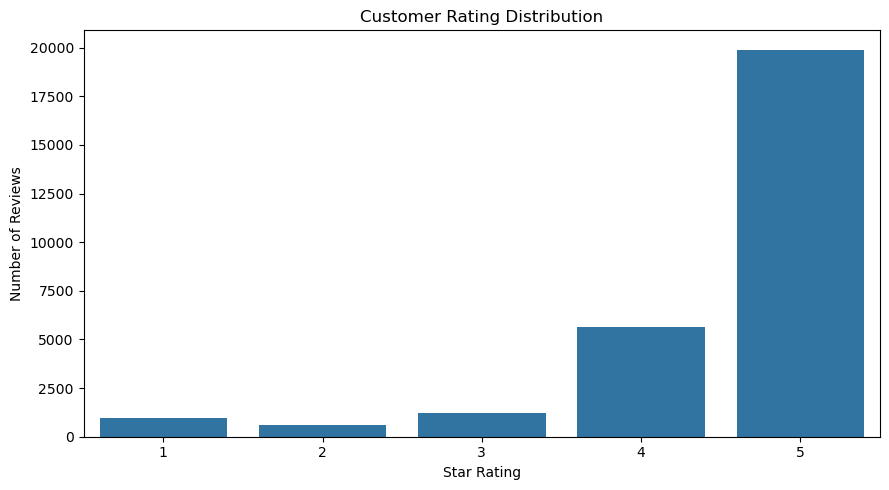

In [16]:
# Calculate rating distribution
rating_counts = df["reviews.rating"].value_counts().sort_index()

print("Customer Rating Distribution:\n")
display(rating_counts.rename("Number of Reviews").to_frame())

# Visualize rating distribution
plt.figure(figsize=(9, 5))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values
)

plt.title("Customer Rating Distribution")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.xticks([0, 1, 2, 3, 4], [1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()

### Interpretation of Customer Rating Distribution

The rating distribution shows how customers have evaluated the products.

Higher ratings (4 and 5 stars) generally indicate positive customer experiences, while lower ratings (1 and 2 stars) indicate dissatisfaction.

A rating of 3 represents a middle rating and should not automatically be treated as neutral sentiment without further analysis.

The findings will help establish an initial understanding of customer satisfaction before applying NLP-based sentiment analysis.

## 15. Product Category Distribution Analysis

Product categories help classify customer reviews according to the type of product being reviewed.

This section examines the distribution of records across the available primary product categories.

The analysis helps identify which product categories contribute the most customer feedback to the dataset.

Top Product Categories:



,Number of Reviews
primaryCategories,
Electronics,13995
Health & Beauty,12071
"Toys & Games,Electronics",1676
"Office Supplies,Electronics",386
"Electronics,Media",185
Office Supplies,9
Animals & Pet Supplies,6
Home & Garden,2
"Electronics,Furniture",2


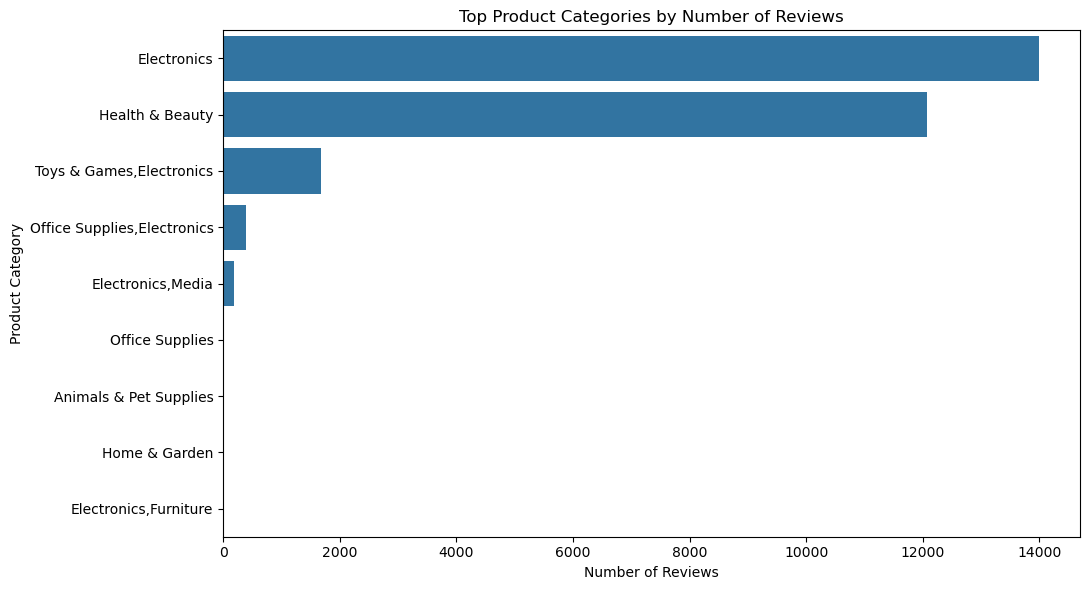

In [23]:
# Calculate product category distribution
category_counts = (
    df["primaryCategories"]
    .value_counts()
    .head(15)
)

print("Top Product Categories:\n")
display(category_counts.rename("Number of Reviews").to_frame())

# Visualize category distribution
plt.figure(figsize=(11, 6))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("Top Product Categories by Number of Reviews")
plt.xlabel("Number of Reviews")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

### Interpretation of Product Category Distribution

The category distribution highlights the product categories with the highest number of customer reviews.

Categories with more reviews provide a larger amount of customer feedback for analysis.

This information will be useful for comparing customer satisfaction and identifying common complaints across product categories.

## 16. Key Findings from Product Category Analysis

The category distribution indicates that Electronics and Health & Beauty account for the majority of customer reviews.

Electronics contains 13,995 reviews, making it the largest category, followed by Health & Beauty with 12,071 reviews.

The remaining categories contribute a comparatively smaller number of observations.

These findings indicate that the dataset is mainly concentrated in two product categories. Therefore, further category-wise analysis will focus on the available category distribution while considering the imbalance in review counts.

## 17. Customer Review Text Analysis

Customer review text is the primary input for Natural Language Processing (NLP) in this project.

In this section, the length of customer reviews is analysed using word counts.

The analysis helps understand how much textual information customers provide and whether reviews are generally short or detailed.

This information is useful for planning text preprocessing and sentiment analysis.

Review Word Count Statistics:



,review_word_count
count,28332.000000
mean,25.945009
std,37.075899
min,1.000000
25%,10.000000
50%,17.000000
75%,31.000000
max,1539.000000


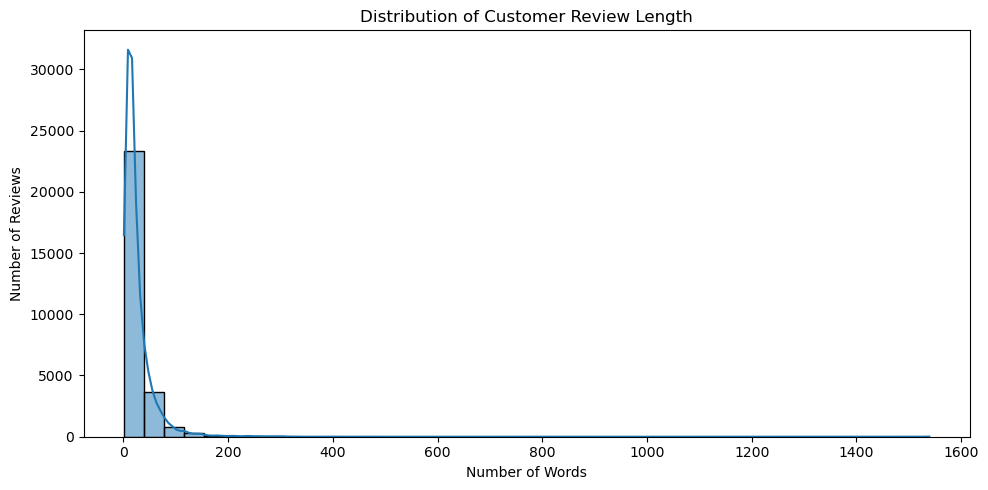

In [25]:
# Calculate the number of words in each review
df["review_word_count"] = df["reviews.text"].astype(str).apply(
    lambda text: len(text.split())
)

print("Review Word Count Statistics:\n")
display(df["review_word_count"].describe().to_frame())

# Visualize review length distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    df["review_word_count"],
    bins=40,
    kde=True
)

plt.title("Distribution of Customer Review Length")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

### Interpretation of Review Text Length

The review length distribution provides an overview of the amount of textual feedback submitted by customers.

Short reviews may contain limited information, whereas longer reviews may describe multiple aspects of the customer experience.

The word count analysis will help understand the characteristics of textual data before applying NLP techniques.

## 18. Customer Review Date Analysis

Review dates help identify the time distribution of customer feedback.

In this section, the review date attribute is converted into a datetime format and analysed to identify the earliest and latest review dates.

The monthly distribution of customer reviews is also examined to understand changes in review activity over time.

The original review date column is preserved, and a separate datetime column is created for analysis.

In [27]:
# Convert review dates into datetime format
df["review_date"] = pd.to_datetime(
    df["reviews.date"],
    errors="coerce",
    utc=True
)

# Calculate date statistics
print("Review Date Analysis\n")

print("Earliest Review Date:", df["review_date"].min())
print("Latest Review Date:", df["review_date"].max())

print("\nValid Dates:", df["review_date"].notna().sum())
print("Invalid or Missing Dates:", df["review_date"].isna().sum())

Review Date Analysis

Earliest Review Date: 2009-02-26 00:00:00+00:00
Latest Review Date: 2019-03-25 00:00:00+00:00

Valid Dates: 28270
Invalid or Missing Dates: 62


## 19. Monthly Customer Review Trend

Monthly review trends help identify periods with higher or lower customer feedback activity.

The review records are grouped by month, and the total number of reviews is calculated for each month.

A line chart is used to visualize the monthly distribution of customer reviews.

Monthly Review Distribution:



,Number of Reviews
review_date,
2009-02-01 00:00:00+00:00,1
2009-03-01 00:00:00+00:00,0
2009-04-01 00:00:00+00:00,0
2009-05-01 00:00:00+00:00,1
2009-06-01 00:00:00+00:00,0
...,...
2018-11-01 00:00:00+00:00,2
2018-12-01 00:00:00+00:00,3
2019-01-01 00:00:00+00:00,3


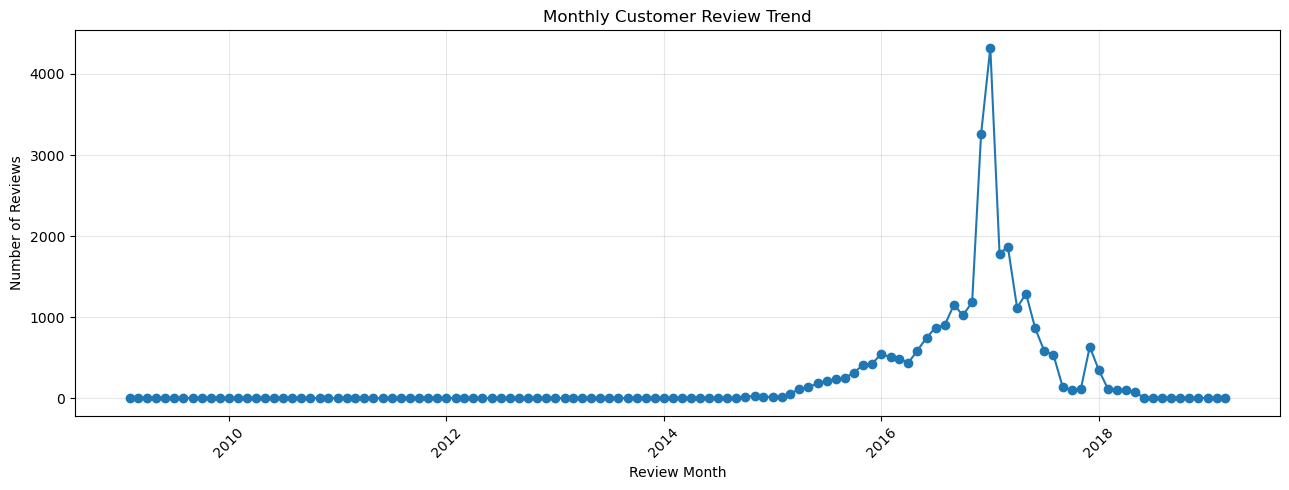

In [29]:
# Group valid review dates by month
monthly_reviews = (
    df.dropna(subset=["review_date"])
      .set_index("review_date")
      .resample("MS")
      .size()
)

print("Monthly Review Distribution:\n")
display(monthly_reviews.to_frame(name="Number of Reviews"))

# Plot monthly review trend
plt.figure(figsize=(13, 5))

plt.plot(
    monthly_reviews.index,
    monthly_reviews.values,
    marker="o"
)

plt.title("Monthly Customer Review Trend")
plt.xlabel("Review Month")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation of Monthly Review Trends

The monthly review trend illustrates how customer feedback is distributed over time.

Months with higher review counts indicate greater review activity, while months with lower counts indicate comparatively less feedback.

This analysis provides a time-based understanding of the dataset and can support further trend analysis in the final customer intelligence dashboard.

## 20. Monthly Review Trend Analysis Findings

The monthly review distribution contains 122 monthly periods.

The dataset covers customer reviews from February 2009 to March 2019. Some months contain zero review records, indicating that customer feedback was not distributed uniformly across the entire period.

This time-based analysis provides an overview of changes in customer review activity and will support further business analysis.

In [31]:
# Identify the month with the highest review activity
peak_month = monthly_reviews.idxmax()
peak_reviews = monthly_reviews.max()

# Identify the month with the lowest non-zero review activity
non_zero_months = monthly_reviews[monthly_reviews > 0]

lowest_month = non_zero_months.idxmin()
lowest_reviews = non_zero_months.min()

print("Monthly Review Trend Summary")
print("--------------------------------")
print("Total Months:", len(monthly_reviews))
print("Peak Review Month:", peak_month.strftime("%B %Y"))
print("Highest Monthly Reviews:", peak_reviews)
print("Lowest Active Month:", lowest_month.strftime("%B %Y"))
print("Lowest Non-zero Monthly Reviews:", lowest_reviews)

Monthly Review Trend Summary
--------------------------------
Total Months: 122
Peak Review Month: January 2017
Highest Monthly Reviews: 4322
Lowest Active Month: February 2009
Lowest Non-zero Monthly Reviews: 1


## 21. Key Findings from Monthly Review Trend Analysis

The monthly review trend analysis identified 122 monthly periods in the dataset.

January 2017 recorded the highest review activity, with 4,322 customer reviews. February 2009 recorded the lowest non-zero activity, with only one review.

The findings indicate that customer review activity varied significantly over time.

These observations provide a foundation for understanding historical customer feedback patterns and identifying periods of increased review activity.

## 22. Overall Exploratory Data Analysis Summary

The Exploratory Data Analysis was performed on the Datafiniti Amazon Product Consumer Reviews dataset.

The dataset contains 28,332 customer review records and 24 attributes.

The major findings are:

1. No completely duplicated records were identified.
2. Customer review text, ratings, review dates, product names, brands, and categories are available.
3. Electronics and Health & Beauty account for the majority of customer reviews.
4. The average customer review contains approximately 26 words.
5. Five-star ratings represent the largest portion of the dataset.
6. January 2017 recorded the highest monthly review activity, with 4,322 reviews.
7. Some optional attributes contain substantial missing values, particularly purchase indicators and helpfulness information.

The analysis confirms that the dataset contains useful information for customer sentiment analysis, theme identification, and business intelligence.

The findings also highlight data quality issues that must be addressed during the data cleaning and preprocessing stage.

In [33]:
# Overall EDA summary

total_reviews = len(df)
total_columns = len(df.columns)

rating_4_5 = df["reviews.rating"].isin([4, 5]).sum()
rating_1_2 = df["reviews.rating"].isin([1, 2]).sum()
rating_3 = (df["reviews.rating"] == 3).sum()

print("FINAL EDA SUMMARY")
print("=" * 40)

print("Total Reviews:", total_reviews)
print("Total Attributes:", total_columns)
print("Duplicate Records:", df.duplicated().sum())

print("\nRating Analysis:")
print("4-5 Star Reviews:", rating_4_5)
print("4-5 Star Percentage:", round(rating_4_5 / total_reviews * 100, 2), "%")
print("1-2 Star Reviews:", rating_1_2)
print("3 Star Reviews:", rating_3)

print("\nReview Text Analysis:")
print("Average Words:", round(df["review_word_count"].mean(), 2))

print("\nMonthly Trend:")
print("Peak Month:", monthly_reviews.idxmax().strftime("%B %Y"))
print("Peak Reviews:", monthly_reviews.max())

print("\nDate Validation:")
print("Valid Review Dates:", df["review_date"].notna().sum())
print("Invalid Review Dates:", df["review_date"].isna().sum())

FINAL EDA SUMMARY
Total Reviews: 28332
Total Attributes: 26
Duplicate Records: 0

Rating Analysis:
4-5 Star Reviews: 25545
4-5 Star Percentage: 90.16 %
1-2 Star Reviews: 1581
3 Star Reviews: 1206

Review Text Analysis:
Average Words: 25.95

Monthly Trend:
Peak Month: January 2017
Peak Reviews: 4322

Date Validation:
Valid Review Dates: 28270
Invalid Review Dates: 62


## 23. Conclusion

The Exploratory Data Analysis provided an understanding of the structure, distribution, and quality of the customer review dataset.

The dataset is suitable for further analysis because it contains customer feedback text, ratings, product information, and review dates.

However, several attributes contain missing values and require appropriate handling.

The next stage will focus on data cleaning, preprocessing, handling missing values, and preparing a structured dataset for Natural Language Processing and machine learning.



## 24. Original and Derived Attributes

The original dataset contains 24 attributes.

During exploratory analysis, two additional derived attributes were created:

1. review_word_count: Represents the number of words in each customer review.
2. review_date: Stores the converted datetime representation of the original review date.

Therefore, the working DataFrame contains 26 columns, including the two derived attributes.

In [34]:
print("Original Dataset Attributes: 24")
print("Additional EDA Attributes: 2")
print("Current DataFrame Attributes:", df.shape[1])

print("\nAdditional Attributes:")
print(["review_word_count", "review_date"])

Original Dataset Attributes: 24
Additional EDA Attributes: 2
Current DataFrame Attributes: 26

Additional Attributes:
['review_word_count', 'review_date']


## 25. Inspection of Invalid Review Dates

During datetime conversion, 62 records could not be converted into valid datetime values.

This section examines the original date values of these records to understand the possible reasons for conversion failures.

These records will be handled during the data cleaning stage.

In [35]:
# Identify records with invalid converted dates
invalid_date_records = df[df["review_date"].isna()]

print("Total Invalid Date Records:", len(invalid_date_records))

display(
    invalid_date_records[
        ["reviews.date", "reviews.text", "reviews.rating"]
    ].head(10)
)

Total Invalid Date Records: 62


,reviews.date,reviews.text,reviews.rating
8344,2014-06-14T05:00:00Z,"After discarding and getting rid of broken cd cases, broken cds, and selecting those ones we rea...",5
8346,2014-06-19T05:00:00Z,My initial impression of this was very good. The material is nicer than the shiny stuff on my Ha...,2
12086,2015-09-10T00:00:00Z,With an Income Tax Preparation practice I'm on my laptop 10 hours a day entering data. Using the...,5
12087,2015-09-17T00:00:00Z,"Simple in its design, with multiple angles, the mesh keeps your laptop cool, the cord keeper in ...",4
12088,2015-10-26T00:00:00Z,Can't seem to say enough about this awesome stand. This allows me to utilize my laptop monitor a...,5
12089,2015-10-26T00:00:00Z,Can't seem to say enough about this awesome stand. This allows me to utilize my laptop monitor a...,5
12090,2015-10-26T00:00:00Z,Can't seem to say enough about this awesome stand. This allows me to utilize my laptop monitor a...,5
12091,2016-02-20T00:00:00Z,The two guard stops at the bottom are WAY TOO HIGH. They dig into my wrists are are painful afte...,2
12093,2015-10-01T00:00:00Z,Every other laptop cooler I have purchased has a USB plug to run a fan. Got tired of the fans ma...,4
12094,2015-10-01T00:00:00Z,Every other laptop cooler I have purchased has a USB plug to run a fan. Got tired of the fans ma...,4


## 26. Verification of Date Conversion

The initial datetime conversion identified 62 records as invalid.

However, inspection of the original date values indicates that some records may contain valid date formats that were not interpreted correctly during the initial conversion.

Therefore, the dates are reprocessed using mixed-format datetime parsing.

The purpose is to recover valid dates without deleting original records.

In [37]:
# Reprocess dates using mixed-format parsing
df["review_date"] = pd.to_datetime(
    df["reviews.date"],
    format="mixed",
    errors="coerce",
    utc=True
)

# Verify the results
valid_dates = df["review_date"].notna().sum()
invalid_dates = df["review_date"].isna().sum()

print("Date Conversion Verification")
print("--------------------------------")
print("Total Records:", len(df))
print("Valid Dates:", valid_dates)
print("Invalid Dates:", invalid_dates)

print("\nRemaining Invalid Date Examples:")

display(
    df.loc[
        df["review_date"].isna(),
        ["reviews.date", "reviews.text"]
    ].head(10)
)

Date Conversion Verification
--------------------------------
Total Records: 28332
Valid Dates: 28332
Invalid Dates: 0

Remaining Invalid Date Examples:


,reviews.date,reviews.text


## 27. Final Date Validation

The review date column was reprocessed using mixed-format datetime parsing to ensure that different date formats were correctly recognized.

The final validation confirmed that all 28,332 records contain valid review dates. No invalid or missing dates remain after conversion.

### Validation Results

- Total Records: 28,332
- Valid Review Dates: 28,332
- Invalid Review Dates: 0
- Date Conversion Success: 100%

### Conclusion

The date conversion process was successfully completed. The cleaned review date column is now suitable for monthly trend analysis, time-based comparisons, and further data processing.

In [38]:
print("FINAL DATE VALIDATION")
print("---------------------")
print("Total Records:", len(df))
print("Valid Dates:", df["review_date"].notna().sum())
print("Invalid Dates:", df["review_date"].isna().sum())
print("Date Conversion Success:",
      round((df["review_date"].notna().mean()) * 100, 2), "%")

FINAL DATE VALIDATION
---------------------
Total Records: 28332
Valid Dates: 28332
Invalid Dates: 0
Date Conversion Success: 100.0 %


## 28. Overall Conclusion of Data Exploration

The exploratory data analysis provided an initial understanding of the Consumer Reviews dataset.

The dataset contains 28,332 customer reviews and 24 original attributes. The analysis identified the rating distribution, product category distribution, missing values, review text characteristics, and monthly review trends.

Key findings include:

1. The dataset contains 28,332 records and 24 original attributes.
2. No duplicate records were identified.
3. Approximately 90.16% of reviews have ratings of 4 or 5 stars.
4. Electronics and Health & Beauty are the major product categories.
5. The average review length is approximately 25.95 words.
6. January 2017 recorded the highest number of reviews, with 4,322 reviews.
7. All review dates were successfully converted, achieving 100% date validation.

This exploration provides the foundation for the next stage of the project, which involves data cleaning, preprocessing, and preparation for sentiment and theme analysis.

In [39]:
print("NOTEBOOK 01 - FINAL VERIFICATION")
print("=" * 40)

print("Dataset Shape:", df.shape)
print("Original Attributes:", 24)
print("EDA Derived Attributes:", 2)
print("Duplicate Records:", df.duplicated().sum())
print("Valid Dates:", df["review_date"].notna().sum())
print("Invalid Dates:", df["review_date"].isna().sum())

print("\nNotebook 01 verification completed.")

NOTEBOOK 01 - FINAL VERIFICATION
Dataset Shape: (28332, 26)
Original Attributes: 24
EDA Derived Attributes: 2
Duplicate Records: 0
Valid Dates: 28332
Invalid Dates: 0

Notebook 01 verification completed.
